# Modelagem: previsão de churn de clientes de um banco

Segunda etapa do projeto: usa o dataset tratado no notebook `01_eda` para criar, comparar e avaliar os modelos.

In [1]:
import sys
from pathlib import Path
sys.path.append(str(Path.cwd().parent))   # permite importar o pacote src a partir da pasta notebooks/

import pickle

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (
    classification_report, ConfusionMatrixDisplay,
    make_scorer, fbeta_score
)

from imblearn.over_sampling import SMOTE
from imblearn.under_sampling import NearMiss
from imblearn.pipeline import Pipeline as ImbPipeline

from src.config import RANDOM_STATE, DADOS_TRATADOS, MODELO_FINAL, PASTA_FIGURAS
from src.modelagem import avaliar_busca_aninhada, contar_treinos, mostrar_hiperparametros
from src.visualizacao import aplicar_tema

np.random.seed(RANDOM_STATE)
aplicar_tema()

In [2]:
df = pd.read_csv(DADOS_TRATADOS) # df tratado gerado no notebook 01_eda
df.head()

,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited,Satisfaction Score,Card Type,Point Earned
0,619,France,Female,42,2,0.00,1,1,1,101348.88,1,2,DIAMOND,464
1,608,Spain,Female,41,1,83807.86,1,0,1,112542.58,0,3,DIAMOND,456
2,502,France,Female,42,8,159660.80,3,1,0,113931.57,1,3,DIAMOND,377
3,699,France,Female,39,1,0.00,2,0,0,93826.63,0,5,GOLD,350
4,850,Spain,Female,43,2,125510.82,1,1,1,79084.10,0,5,GOLD,425


# Modelo

## Preparação dos dados

In [3]:
x = df.drop(columns='Exited')
y = df['Exited']

x_treino, x_teste, y_treino, y_teste = train_test_split(
    x, y,
    test_size=0.2,
    stratify=y,               # mantém a proporção de churn nos dois conjuntos
    random_state=RANDOM_STATE
)

print(f'Treino: {x_treino.shape[0]:,} linhas | churn = {y_treino.mean():.2%}')
print(f'Teste:  {x_teste.shape[0]:,} linhas | churn = {y_teste.mean():.2%}')

Treino: 8,000 linhas | churn = 20.38%
Teste:  2,000 linhas | churn = 20.40%


Pipeline de pré-processamento:

O `ColumnTransformer` contém as duas transformações necessárias juntas. Dentro de uma `Pipeline`, ele é reajustado a cada dobra da validação cruzada — é isso que elimina o vazamento.

In [4]:
cols_categoricas = ['Geography', 'Gender', 'Card Type']
cols_numericas = [c for c in x.columns if c not in cols_categoricas]

print('Categóricas:', cols_categoricas)
print('Numéricas:  ', cols_numericas)

Categóricas: ['Geography', 'Gender', 'Card Type']
Numéricas:   ['CreditScore', 'Age', 'Tenure', 'Balance', 'NumOfProducts', 'HasCrCard', 'IsActiveMember', 'EstimatedSalary', 'Satisfaction Score', 'Point Earned']


In [5]:
preprocessador = ColumnTransformer(
    transformers=[
        ('cat', OneHotEncoder(drop='if_binary', handle_unknown='ignore'), cols_categoricas),
        ('num', StandardScaler(), cols_numericas),
    ]
)

## Escolhendo a métrica de otimização

Nesse contexto, é importante que o foco em otimizar o modelo seja em aumentar a métrica de **RECALL**, pois essa métrica tem relação direta com os **clientes de churn**: um recall ruim significa que o modelo não é bom para prever os clientes que teram churn.

No entanto, é uma péssima estratégia pensar em **recall puro** e aqui está o problema: **um modelo que classifica todo mundo como churn tem recall de 100%**.

Recall sozinho é uma métrica que pode ser trapaceada. Na tentativa de aumentar puramente o recall, a precisão sofre um efeito negativo quase que na mesma proporção.

A escolha aqui é o **F2-score**: a média harmônica ponderada entre precisão e recall, com peso 4× maior no recall.

$$F_\beta = (1 + \beta^2) \cdot \frac{precisão \cdot recall}{\beta^2 \cdot precisão + recall}, \quad \beta = 2$$

Isso traduz a regra de negócio correta: **perder um cliente custa mais caro do que oferecer um desconto desnecessário — mas não infinitamente mais caro.**

In [6]:
f2_scorer = make_scorer(fbeta_score, beta=2)

METRICAS = {
    'f2': f2_scorer,
    'recall': 'recall',
    'precision': 'precision',
    'f1': 'f1'
    }

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

## Baselines

Antes de otimizar qualquer coisa, é preciso saber o que significa "bom". Três referências:

In [7]:
dummy = DummyClassifier(strategy='most_frequent')

lr_baseline = LogisticRegression(max_iter=1000, random_state=RANDOM_STATE)

dt_baseline = DecisionTreeClassifier(max_depth=10, random_state=RANDOM_STATE)

lista_baselines = [dummy, lr_baseline, dt_baseline]

tabelas = []
for model in lista_baselines:

    pipe = Pipeline([('prep', preprocessador), ('modelo', model)])

    resultados = cross_validate(pipe, x_treino, y_treino, cv=cv, scoring=METRICAS, n_jobs=-1)

    coluna = pd.DataFrame(resultados).filter(like='test_').mean().round(3)
    coluna.index = coluna.index.str.replace('test_', '')

    tabelas.append(coluna.rename(type(model).__name__))

pd.concat(tabelas, axis=1)

,DummyClassifier,LogisticRegression,DecisionTreeClassifier
f2,0.0,0.238,0.494
recall,0.0,0.207,0.471
precision,0.0,0.598,0.616
f1,0.0,0.307,0.534


O `DummyClassifier` zera em recall — ele nunca prevê churn. É o piso absoluto e mostra por que **acurácia não serve aqui**: chutar "ninguém sai" já acerta ~80% dos casos.

## Criação dos modelos

Aqui é a etapa de criar os modelos. Vou utilizar os algoritmos `DecisionTree`, `RandomForest` e `LogisticRegression`. Para cada modelo criado vou criar 3 versões, validar suas métricas e compará-los.

Nesse passo, para obter os melhores hiperparâmetros e maximizar as métricas de cada modelo, vou usar o `RandomizedSearchCV`, que testa algumas combinações de hiperparâmetros e devolve a melhor pela métrica escolhida.

### Decision Tree


In [8]:
inner_cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=RANDOM_STATE)
outer_cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

pipe_dt = Pipeline([
    ('prep', preprocessador),
    ('modelo', DecisionTreeClassifier(random_state=RANDOM_STATE)),
])

param_rs_dt = {
    'modelo__criterion': ['gini', 'entropy'],
    'modelo__max_depth': np.linspace(4, 14, 6, dtype=int),
    'modelo__min_samples_split': np.linspace(10, 60, 4, dtype=int),
    'modelo__min_samples_leaf': np.linspace(5, 50, 4, dtype=int),
    'modelo__class_weight': [None, 'balanced'],   # penalização por peso de classe
}

contar_treinos(param_rs_dt, inner_cv)

384 combinações x 3 dobras = 1152 treinos


In [9]:
dt_nested_rs, dt_nested_rs_scores = avaliar_busca_aninhada(
    pipe_dt, param_rs_dt, x_treino, y_treino, METRICAS, inner_cv, outer_cv
)

F2 em cada dobra externa: [0.621 0.612 0.624 0.638 0.653]
Média dos F2: 0.630

Melhores hiperparâmetros:
  min_samples_split    = 60
  min_samples_leaf     = 20
  max_depth            = 8
  criterion            = entropy
  class_weight         = balanced


Explorando os resultados da busca

O atributo `cv_results_` guarda o desempenho de todas as combinações testadas. Vou transformar isso num DataFrame para observar o desempenho geral de cada hiperparâmetro.

In [10]:
df_cv_dt = pd.DataFrame(dt_nested_rs.cv_results_)

colunas_uteis = ([c for c in df_cv_dt.columns if c.startswith('param_')]
                 + ['mean_test_f2', 'mean_test_recall', 'mean_test_precision', 'mean_train_f2'])

df_cv_dt[colunas_uteis].sort_values('mean_test_f2', ascending=False).head(10).round(3)

,param_modelo__min_samples_split,param_modelo__min_samples_leaf,param_modelo__max_depth,param_modelo__criterion,param_modelo__class_weight,mean_test_f2,mean_test_recall,mean_test_precision,mean_train_f2
35,60,20,8,entropy,balanced,0.652,0.743,0.438,0.727
38,43,35,10,entropy,balanced,0.650,0.745,0.431,0.724
9,43,50,8,gini,balanced,0.649,0.745,0.428,0.706
1,43,35,10,gini,balanced,0.648,0.734,0.441,0.722
17,10,35,12,entropy,balanced,0.646,0.739,0.430,0.725
0,10,50,12,gini,balanced,0.646,0.739,0.429,0.706
32,26,20,8,entropy,balanced,0.645,0.736,0.432,0.730
18,60,50,12,entropy,balanced,0.642,0.728,0.436,0.702
8,60,20,14,entropy,balanced,0.640,0.722,0.441,0.750
3,10,50,8,entropy,balanced,0.639,0.723,0.435,0.699


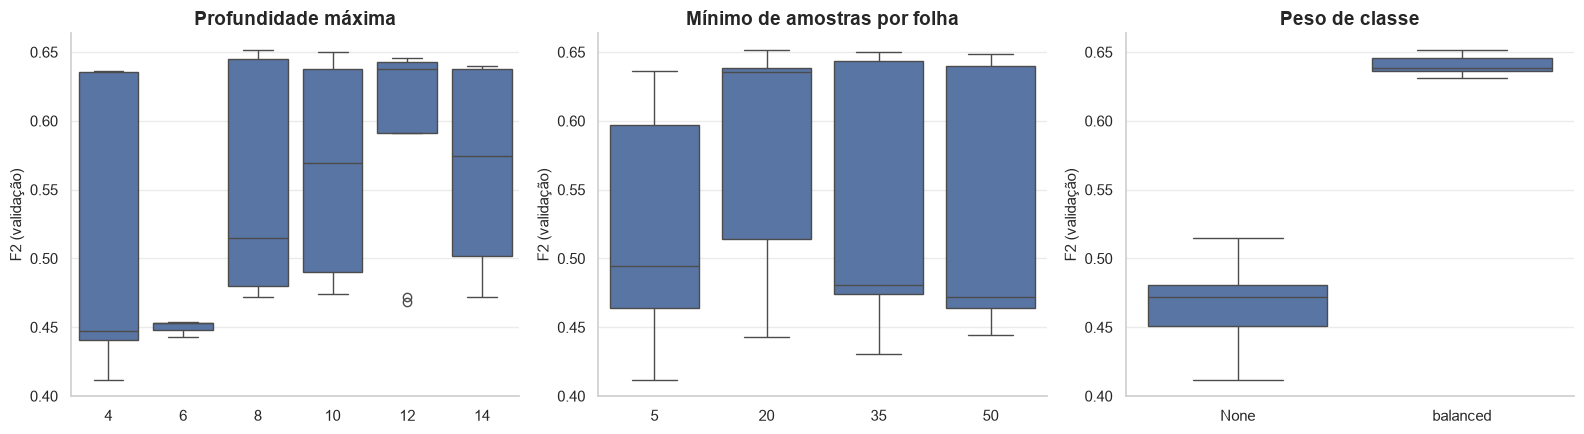

In [11]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))

for ax, p, titulo in zip(
    axes,
    ['param_modelo__max_depth', 'param_modelo__min_samples_leaf', 'param_modelo__class_weight'],
    ['Profundidade máxima', 'Mínimo de amostras por folha', 'Peso de classe']
):
    dados = df_cv_dt[[p, 'mean_test_f2']].copy()

    if p != 'param_modelo__class_weight':
        ordem = sorted(dados[p].dropna().unique())
        dados[p] = dados[p].astype(str)
        ordem = [str(x) for x in ordem]
    else:
        dados[p] = dados[p].map(lambda v: 'None' if pd.isna(v) else str(v))   # o None do class_weight vira texto para aparecer no gráfico
        ordem = sorted(dados[p].unique())

    sns.boxplot(data=dados, x=p, y='mean_test_f2', ax=ax, order=ordem)
    ax.set_title(titulo); ax.set_xlabel(''); ax.set_ylabel('F2 (validação)')

plt.tight_layout(); plt.show()

Agora é possível entender quais hiperparâmetros podem ser melhores no desempenho do modelo

#### Decision Tree + SMOTE (Oversample)

In [12]:
pipe_dt_smote = ImbPipeline([
    ('prep', preprocessador),
    ('smote', SMOTE(random_state=RANDOM_STATE)),
    ('modelo', DecisionTreeClassifier(random_state=RANDOM_STATE)),
])

param_rs_dt_smote = {
    'smote__sampling_strategy': [0.3, 0.5, 0.8, 1.0],
    'modelo__criterion': ['gini', 'entropy'],
    'modelo__max_depth': np.linspace(4, 14, 6, dtype=int),
    'modelo__min_samples_split': np.linspace(10, 60, 4, dtype=int),
    'modelo__min_samples_leaf': np.linspace(5, 50, 4, dtype=int),
}

contar_treinos(param_rs_dt_smote, inner_cv)

768 combinações x 3 dobras = 2304 treinos


In [13]:
dt_nested_rs_smote, dt_nested_rs_smote_scores = avaliar_busca_aninhada(
    pipe_dt_smote, param_rs_dt_smote, x_treino, y_treino, METRICAS, inner_cv, outer_cv
)

F2 em cada dobra externa: [0.614 0.637 0.636 0.601 0.598]
Média dos F2: 0.617

Melhores hiperparâmetros:
  smote__sampling_strategy = 1.0
  min_samples_split    = 60
  min_samples_leaf     = 35
  max_depth            = 4
  criterion            = entropy


#### DecisionTree + Nearmiss (Undersample)

In [14]:
pipe_dt_nearmiss = ImbPipeline([
    ('prep', preprocessador),
    ('nearmiss', NearMiss()),
    ('modelo', DecisionTreeClassifier(random_state=RANDOM_STATE)),
])

param_rs_dt_nearmiss = {
    'nearmiss__version': [1, 2, 3],
    'modelo__criterion': ['gini', 'entropy'],
    'modelo__max_depth': np.linspace(4, 14, 6, dtype=int),
    'modelo__min_samples_split': np.linspace(10, 60, 4, dtype=int),
    'modelo__min_samples_leaf': np.linspace(5, 50, 4, dtype=int),
}

contar_treinos(param_rs_dt_nearmiss, inner_cv)

576 combinações x 3 dobras = 1728 treinos


In [15]:
dt_nested_rs_nearmiss, dt_nested_rs_nearmiss_scores = avaliar_busca_aninhada(
    pipe_dt_nearmiss, param_rs_dt_nearmiss, x_treino, y_treino, METRICAS, inner_cv, outer_cv
)

F2 em cada dobra externa: [0.648 0.635 0.646 0.615 0.622]
Média dos F2: 0.633

Melhores hiperparâmetros:
  nearmiss__version    = 2
  min_samples_split    = 10
  min_samples_leaf     = 50
  max_depth            = 14
  criterion            = entropy


### Random Forest

In [16]:
pipe_rf = Pipeline([
    ('prep', preprocessador),
    ('modelo', RandomForestClassifier(random_state=RANDOM_STATE)),
])

param_rs_rf = {
    'modelo__max_depth': [8, 12, 16],
    'modelo__min_samples_leaf': [5, 20],
    'modelo__max_features': ['sqrt', 0.5],
    'modelo__class_weight': [None, 'balanced'],
}

contar_treinos(param_rs_rf, inner_cv)

24 combinações x 3 dobras = 72 treinos


In [17]:
rf_nested_rs, rf_nested_rs_scores = avaliar_busca_aninhada(
    pipe_rf, param_rs_rf, x_treino, y_treino, METRICAS, inner_cv, outer_cv
)

C:\Users\Darlei\Downloads\bank-customer-churn\bank-customer-churn-prediction\.venv\Lib\site-packages\sklearn\model_selection\_search.py:327: UserWarning: The total space of parameters 24 is smaller than n_iter=40. Running 24 iterations. For exhaustive searches, use GridSearchCV.
  warnings.warn(


F2 em cada dobra externa: [0.672 0.681 0.703 0.686 0.675]
Média dos F2: 0.683

Melhores hiperparâmetros:
  min_samples_leaf     = 20
  max_features         = 0.5
  max_depth            = 8
  class_weight         = balanced


#### Random Forest + SMOTE (Oversample)

In [18]:
pipe_rf_smote = ImbPipeline([
    ('prep', preprocessador),
    ('smote', SMOTE(random_state=RANDOM_STATE)),
    ('modelo', RandomForestClassifier(random_state=RANDOM_STATE, n_jobs=-1)),
])

param_rs_rf_smote = {
    'smote__sampling_strategy': [0.3, 0.5, 0.8, 1.0],
    'modelo__max_depth': [8, 12, 16],
    'modelo__min_samples_leaf': [5, 20],
    'modelo__max_features': ['sqrt', 0.5],
}

contar_treinos(param_rs_rf_smote, inner_cv)

48 combinações x 3 dobras = 144 treinos


In [19]:
rf_nested_rs_smote, rf_nested_rs_smote_scores = avaliar_busca_aninhada(
    pipe_rf_smote, param_rs_rf_smote, x_treino, y_treino, METRICAS, inner_cv, outer_cv
)

F2 em cada dobra externa: [0.636 0.631 0.663 0.607 0.656]
Média dos F2: 0.639

Melhores hiperparâmetros:
  smote__sampling_strategy = 1.0
  min_samples_leaf     = 20
  max_features         = 0.5
  max_depth            = 8


#### Random Forest + Nearmiss (Undersample)

In [20]:
pipe_rf_nearmiss = ImbPipeline([
    ('prep', preprocessador),
    ('nearmiss', NearMiss()),
    ('modelo', RandomForestClassifier(random_state=RANDOM_STATE, n_jobs=-1)),
])

param_rs_rf_nearmiss = {
    'nearmiss__version': [1, 2, 3],
    'modelo__max_depth': [8, 12, 16],
    'modelo__min_samples_leaf': [5, 20],
    'modelo__max_features': ['sqrt', 0.5],
}

contar_treinos(param_rs_rf_nearmiss, inner_cv)

36 combinações x 3 dobras = 108 treinos


In [21]:
rf_nested_rs_nearmiss, rf_nested_rs_nearmiss_scores = avaliar_busca_aninhada(
    pipe_rf_nearmiss, param_rs_rf_nearmiss, x_treino, y_treino, METRICAS, inner_cv, outer_cv
)

C:\Users\Darlei\Downloads\bank-customer-churn\bank-customer-churn-prediction\.venv\Lib\site-packages\sklearn\model_selection\_search.py:327: UserWarning: The total space of parameters 36 is smaller than n_iter=40. Running 36 iterations. For exhaustive searches, use GridSearchCV.
  warnings.warn(


F2 em cada dobra externa: [0.652 0.638 0.666 0.64  0.659]
Média dos F2: 0.651

Melhores hiperparâmetros:
  nearmiss__version    = 3
  min_samples_leaf     = 5
  max_features         = sqrt
  max_depth            = 16


### Logistic Regression

In [22]:
pipe_lr = ImbPipeline([
    ('prep', preprocessador),
    ('modelo', LogisticRegression(random_state=RANDOM_STATE, n_jobs=-1)),
])

max_iter = 1000
c = [0.001, 0.01, 0.1, 1, 10]

param_rs_lr = [ # Dois dicionários aqui porque existem parâmetros de não podem ser combinados com outros
    {'modelo__solver' : ['newton-cg', 'lbfgs'], # Apenas compatíveis com l2
     'modelo__penalty' : ['l2'],
     'modelo__max_iter' : [max_iter],
     'modelo__C' : c,
     'modelo__class_weight': [None, 'balanced']},
    {'modelo__solver' : ['liblinear'], # Compatível com l1 e l2
     'modelo__penalty' : ['l1', 'l2'],
     'modelo__max_iter' : [max_iter],
     'modelo__C' : c,
     'modelo__class_weight': [None, 'balanced']},
]

contar_treinos(param_rs_lr, inner_cv)

40 combinações x 3 dobras = 120 treinos


In [23]:
lr_nested_rs, lr_nested_rs_scores = avaliar_busca_aninhada(
    pipe_lr, param_rs_lr, x_treino, y_treino, METRICAS, inner_cv, outer_cv
)

F2 em cada dobra externa: [0.596 0.595 0.621 0.573 0.626]
Média dos F2: 0.602

Melhores hiperparâmetros:
  solver               = liblinear
  penalty              = l1
  max_iter             = 1000
  class_weight         = balanced
  C                    = 0.01


C:\Users\Darlei\Downloads\bank-customer-churn\bank-customer-churn-prediction\.venv\Lib\site-packages\sklearn\linear_model\_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(
C:\Users\Darlei\Downloads\bank-customer-churn\bank-customer-churn-prediction\.venv\Lib\site-packages\sklearn\linear_model\_logistic.py:1407: UserWarning: Inconsistent values: penalty=l1 with l1_ratio=0.0. penalty is deprecated. Please use l1_ratio only.
  warnings.warn(
C:\Users\Darlei\Downloads\bank-customer-churn\bank-customer-churn-prediction\.venv\Lib\site-packages\sklearn\linear_model\_logistic.py:1435: FutureWarning: 'n_jobs' has no effect since 1.8 and will be 

#### Logistic Regression + SMOTE

In [24]:
pipe_lr_smote = ImbPipeline([
    ('prep', preprocessador),
    ('smote', SMOTE(random_state=RANDOM_STATE)),
    ('modelo', LogisticRegression(random_state=RANDOM_STATE, n_jobs=-1)),
])

param_rs_lr_smote = [
    {'smote__sampling_strategy': [0.3, 0.5, 0.8],
     'modelo__solver' : ['newton-cg', 'lbfgs'],
     'modelo__penalty' : ['l2'],
     'modelo__max_iter' : [max_iter],
     'modelo__C' : c},
    {'smote__sampling_strategy': [0.3, 0.5, 0.8, 1.0],
     'modelo__solver' : ['liblinear'],
     'modelo__penalty' : ['l1', 'l2'],
     'modelo__max_iter' : [max_iter],
     'modelo__C' : c},
]

contar_treinos(param_rs_lr_smote, inner_cv)

70 combinações x 3 dobras = 210 treinos


In [25]:
lr_nested_rs_smote, lr_nested_rs_smote_scores = avaliar_busca_aninhada(
    pipe_lr_smote, param_rs_lr_smote, x_treino, y_treino, METRICAS, inner_cv, outer_cv
)

F2 em cada dobra externa: [0.563 0.581 0.598 0.571 0.606]
Média dos F2: 0.584

Melhores hiperparâmetros:
  smote__sampling_strategy = 1.0
  solver               = liblinear
  penalty              = l1
  max_iter             = 1000
  C                    = 1


C:\Users\Darlei\Downloads\bank-customer-churn\bank-customer-churn-prediction\.venv\Lib\site-packages\sklearn\linear_model\_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(
C:\Users\Darlei\Downloads\bank-customer-churn\bank-customer-churn-prediction\.venv\Lib\site-packages\sklearn\linear_model\_logistic.py:1407: UserWarning: Inconsistent values: penalty=l1 with l1_ratio=0.0. penalty is deprecated. Please use l1_ratio only.
  warnings.warn(
C:\Users\Darlei\Downloads\bank-customer-churn\bank-customer-churn-prediction\.venv\Lib\site-packages\sklearn\linear_model\_logistic.py:1435: FutureWarning: 'n_jobs' has no effect since 1.8 and will be 

#### Logistic Regression + NearMiss

In [26]:
pipe_lr_nearmiss = ImbPipeline([
    ('prep', preprocessador),
    ('nearmiss', NearMiss()),
    ('modelo', LogisticRegression(random_state=RANDOM_STATE, n_jobs=-1)),
])

param_rs_lr_nearmiss = [
    {'nearmiss__version': [1, 2, 3],
     'modelo__solver' : ['newton-cg', 'lbfgs'],
     'modelo__penalty' : ['l2'],
     'modelo__max_iter' : [max_iter],
     'modelo__C' : c},
    {'nearmiss__version': [1, 2, 3],
     'modelo__solver' : ['liblinear'],
     'modelo__penalty' : ['l1', 'l2'],
     'modelo__max_iter' : [max_iter],
     'modelo__C' : c},
]

contar_treinos(param_rs_lr_nearmiss, inner_cv)

60 combinações x 3 dobras = 180 treinos


In [27]:
lr_nested_rs_nearmiss, lr_nested_rs_nearmiss_scores = avaliar_busca_aninhada(
    pipe_lr_nearmiss, param_rs_lr_nearmiss, x_treino, y_treino, METRICAS, inner_cv, outer_cv
)

F2 em cada dobra externa: [0.56  0.575 0.59  0.576 0.567]
Média dos F2: 0.574

Melhores hiperparâmetros:
  nearmiss__version    = 2
  solver               = liblinear
  penalty              = l1
  max_iter             = 1000
  C                    = 0.1


C:\Users\Darlei\Downloads\bank-customer-churn\bank-customer-churn-prediction\.venv\Lib\site-packages\sklearn\linear_model\_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(
C:\Users\Darlei\Downloads\bank-customer-churn\bank-customer-churn-prediction\.venv\Lib\site-packages\sklearn\linear_model\_logistic.py:1407: UserWarning: Inconsistent values: penalty=l1 with l1_ratio=0.0. penalty is deprecated. Please use l1_ratio only.
  warnings.warn(
C:\Users\Darlei\Downloads\bank-customer-churn\bank-customer-churn-prediction\.venv\Lib\site-packages\sklearn\linear_model\_logistic.py:1435: FutureWarning: 'n_jobs' has no effect since 1.8 and will be 

## Avaliação final no conjunto de teste

Com todos modelos já criados, treinados e com métricas de validação, vou pegar aquele que teve o maior F2 e testá-lo com dados novos que ainda não foram expostos a ele. Com essa etapa final feita, será possível observar o desempenho do nosso modelo com dados reais e obter as métricas definitivas do melhor modelo.

In [28]:
scores_aninhados = {
    'Decision Tree': dt_nested_rs_scores,
    'Decision Tree + SMOTE': dt_nested_rs_smote_scores,
    'Decision Tree + NearMiss': dt_nested_rs_nearmiss_scores,
    'Random Forest': rf_nested_rs_scores,
    'Random Forest + SMOTE': rf_nested_rs_smote_scores,
    'Random Forest + NearMiss': rf_nested_rs_nearmiss_scores,
    'Logistic Regression': lr_nested_rs_scores,
    'Logistic Regression + SMOTE': lr_nested_rs_smote_scores,
    'Logistic Regression + NearMiss': lr_nested_rs_nearmiss_scores,
}

buscas = {
    'Decision Tree': dt_nested_rs,
    'Decision Tree + SMOTE': dt_nested_rs_smote,
    'Decision Tree + NearMiss': dt_nested_rs_nearmiss,
    'Random Forest': rf_nested_rs,
    'Random Forest + SMOTE': rf_nested_rs_smote,
    'Random Forest + NearMiss': rf_nested_rs_nearmiss,
    'Logistic Regression': lr_nested_rs,
    'Logistic Regression + SMOTE': lr_nested_rs_smote,
    'Logistic Regression + NearMiss': lr_nested_rs_nearmiss,
}

ranking = pd.DataFrame({
    nome: {
        'F2 aninhado': r['test_f2'].mean(),
        'desvio': r['test_f2'].std(),
        'recall': r['test_recall'].mean(),
        'precisão': r['test_precision'].mean(),
        'f1': r['test_f1'].mean(),
    }
    for nome, r in scores_aninhados.items()
}).T.sort_values('F2 aninhado', ascending=False).round(3)

display(ranking)

nome_vencedor = ranking.index[0]
melhor_modelo = buscas[nome_vencedor]
print(f'Modelo escolhido: {nome_vencedor}')

,F2 aninhado,desvio,recall,precisão,f1
Random Forest,0.683,0.011,0.743,0.517,0.610
Random Forest + NearMiss,0.651,0.011,0.707,0.494,0.582
Random Forest + SMOTE,0.639,0.020,0.651,0.594,0.621
Decision Tree + NearMiss,0.633,0.013,0.848,0.315,0.459
Decision Tree,0.630,0.014,0.712,0.433,0.537
Decision Tree + SMOTE,0.617,0.017,0.660,0.503,0.567
Logistic Regression,0.602,0.019,0.707,0.378,0.493
Logistic Regression + SMOTE,0.584,0.016,0.700,0.355,0.469
Logistic Regression + NearMiss,0.574,0.010,0.755,0.293,0.422


Modelo escolhido: Random Forest


Com o nosso modelo vencedor estabelecido, antes de testá-lo, vamos fazer uma breve análise de suas características.

In [29]:
mostrar_hiperparametros(melhor_modelo)

Melhores hiperparâmetros:
  min_samples_leaf     = 20
  max_features         = 0.5
  max_depth            = 8
  class_weight         = balanced


In [30]:
df_cv_melhor_modelo = pd.DataFrame(melhor_modelo.cv_results_)

coluna_score = 'mean_test_f2' if 'mean_test_f2' in df_cv_melhor_modelo.columns else 'mean_test_score'
colunas_parametros = [c for c in df_cv_melhor_modelo.columns if c.startswith('param_')]
metricas = [m for m in [coluna_score, 'mean_test_recall', 'mean_test_precision', 'mean_train_f2']
            if m in df_cv_melhor_modelo.columns]

df_cv_melhor_modelo[colunas_parametros + metricas].sort_values(coluna_score, ascending=False).head(10).round(3)

,param_modelo__min_samples_leaf,param_modelo__max_features,param_modelo__max_depth,param_modelo__class_weight,mean_test_f2,mean_test_recall,mean_test_precision,mean_train_f2
15,20,0.5,8,balanced,0.675,0.735,0.510,0.743
19,20,0.5,12,balanced,0.671,0.729,0.508,0.758
17,20,sqrt,12,balanced,0.668,0.728,0.505,0.751
14,5,0.5,8,balanced,0.668,0.717,0.528,0.776
23,20,0.5,16,balanced,0.666,0.725,0.505,0.757
13,20,sqrt,8,balanced,0.666,0.726,0.501,0.736
12,5,sqrt,8,balanced,0.664,0.709,0.531,0.769
21,20,sqrt,16,balanced,0.663,0.722,0.501,0.749
18,5,0.5,12,balanced,0.656,0.688,0.557,0.898
22,5,0.5,16,balanced,0.653,0.682,0.560,0.921


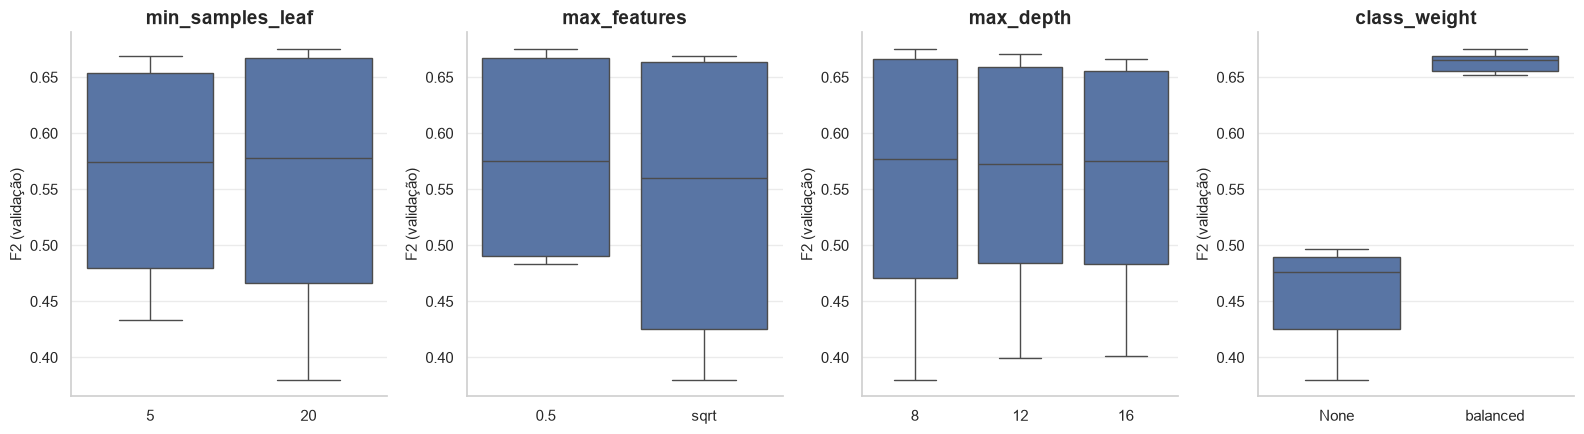

In [31]:
fig, axes = plt.subplots(1, len(colunas_parametros),
                         figsize=(4 * len(colunas_parametros), 4.5), squeeze=False)

for ax, p in zip(axes[0], colunas_parametros):
    dados = df_cv_melhor_modelo[[p, coluna_score]].copy()
    dados[p] = dados[p].map(lambda v: 'None' if pd.isna(v) else str(v))

    if pd.to_numeric(dados[p], errors='coerce').notna().all():
        ordem = sorted(dados[p].unique(), key=float)
    else:
        ordem = sorted(dados[p].unique())

    sns.boxplot(data=dados, x=p, y=coluna_score, ax=ax, order=ordem)
    ax.set_title(p.replace('param_', '').replace('modelo__', ''))
    ax.set_xlabel('')
    ax.set_ylabel('F2 (validação)')

plt.tight_layout()
plt.show()

Aqui conseguimos observar a importância do hiperparâmetro class_weight quando utilizados em dados com classes desbalanceadas.

              precision    recall  f1-score   support

       Ficou      0.928     0.818     0.869      1592
        Saiu      0.514     0.752     0.611       408

    accuracy                          0.804      2000
   macro avg      0.721     0.785     0.740      2000
weighted avg      0.844     0.804     0.817      2000

F2 no teste: 0.689


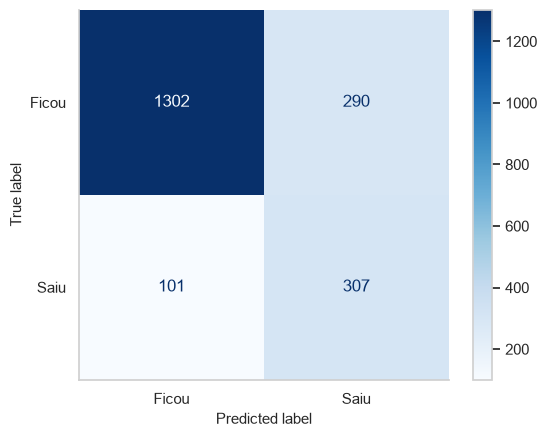

In [32]:
y_pred = melhor_modelo.predict(x_teste)

print(classification_report(y_teste, y_pred, target_names=['Ficou', 'Saiu'], digits=3))
print(f'F2 no teste: {fbeta_score(y_teste, y_pred, beta=2):.3f}')

matriz = ConfusionMatrixDisplay.from_predictions(
    y_teste, y_pred, display_labels=['Ficou', 'Saiu'], cmap='Blues'
)
matriz.ax_.grid(False)
matriz.figure_.savefig(PASTA_FIGURAS / 'matriz_confusao.png', dpi=150, bbox_inches='tight')   # usada no README
plt.show()

Agora com o desempenho real do nosso modelo podemos definir suas principais métricas reais:

- **F2 Score (métrica-alvo): 68.9%**
- **Recall: 75.2%**
- **Acurácia: 80.4%**
- **Precisão: 51.4%**

### Leitura de negócio

Vou colocar o desempenho do modelo no contexto de uma operação, considerando os 2.000 clientes do conjunto de teste, dos quais 408 realmente deixaram o banco:

- **307 clientes em risco foram identificados**, 75,2% dos que realmente sairiam (recall). Esses são os casos em que o time de retenção teria a chance de agir antes da saída.
- **101 clientes saíram sem nenhum alerta.** A saída do cliente sem tentativa de restenção é o erro mais caro.
- **290 clientes receberiam contato desnecessário** — pessoas que ficariam de
qualquer forma. É o erro barato: custa o valor da ação de retenção, não o cliente.

**Limitação.** A precisão de 51,4% mostra que metade dos alertas é falso positivo. Melhorar essa métrica, no caso exigiria aceitar um recall menor, ou seja, deixar mais clientes saírem sem alerta.

Na prática, para cada cliente que o modelo realmente salva, cerca de um
outro é acionado sem necessidade. Se o custo de uma ação de retenção for baixo frente ao valor de um cliente perdido, essa troca compensa. Foi exatamente com essa premissa que decidi escolher o F2 como métrica de otimização.

Entre criar uma campanha para um cliente que não sairia e perder um cliente sem tentar retê-lo, qual dos dois erros priorizar é uma decisão de negócio, não técnica, e depende da relação entre o custo da campanha de retenção e o valor de um cliente.

## Salvando o modelo

Vou salvar o modelo vencedor com o `pickle` para poder usá-lo depois sem refazer toda a validação cruzada aninhada. O objeto salvo é a **pipeline completa** (pré-processamento + Random Forest), treinada com todo o conjunto de treino: ela recebe os dados no mesmo formato do CSV tratado (sem a coluna `Exited`) e já faz o One-Hot Encoding e a padronização sozinha.

In [33]:
MODELO_FINAL.parent.mkdir(exist_ok=True)   # cria a pasta models/ caso ainda não exista

with open(MODELO_FINAL, 'wb') as arquivo:
    pickle.dump(melhor_modelo.best_estimator_, arquivo)

print(f'Modelo salvo em: {MODELO_FINAL.relative_to(MODELO_FINAL.parents[1])}')

Modelo salvo em: models\modelo_churn.pkl


Para conferir, carrego o arquivo salvo e verifico se ele faz exatamente as mesmas previsões no conjunto de teste.

In [34]:
with open(MODELO_FINAL, 'rb') as arquivo:
    modelo_carregado = pickle.load(arquivo)

print(f'Previsões iguais às do modelo original: {(modelo_carregado.predict(x_teste) == y_pred).all()}')

Previsões iguais às do modelo original: True
